In [ ]:
"""

3. Weather Comparison (weather_data.csv, 3 cities × 2 years)

Question: “How do Pune, Delhi, and Chennai differ in climate?”

1:Fill the missing temperatures, ideally by city median.

2:Extract the month and season from the date.

3:Plot monthly average temperature per city in one line chart.

4:Show total rainfall by month in a bar chart.

5:Compare the temperature distributions in a violin or box plot.

6:Plot humidity against rainfall in a scatter plot.

7:Write a conclusion on which city has the most extreme weather.

"""

In [7]:
df =pd.read_csv("C:/Users/HP/Downloads/weather_data.csv")
df

,date,city,temp_c,humidity_pct,rainfall_mm,wind_kmh
0,2024-01-01,Pune,20.0,72.0,0.0,17.0
1,2024-01-02,Pune,18.2,62.0,0.0,8.5
2,2024-01-03,Pune,19.4,59.0,0.0,10.3
3,2024-01-04,Pune,21.1,49.0,0.0,19.5
4,2024-01-05,Pune,19.3,59.0,0.0,13.2
...,...,...,...,...,...,...
2188,2025-12-27,Chennai,26.3,54.0,0.0,19.7
2189,2025-12-28,Chennai,27.1,47.0,0.0,10.9
2190,2025-12-29,Chennai,25.1,62.0,0.0,9.4
2191,2025-12-30,Chennai,25.4,62.0,0.0,11.0


In [12]:
df.isna().sum()
df["temp_c"] = df["temp_c"].fillna(
df.groupby("city")["temp_c"].transform("median"))

C:\Users\HP\AppData\Local\Temp\ipykernel_9308\2647013288.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_9308\2647013288.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


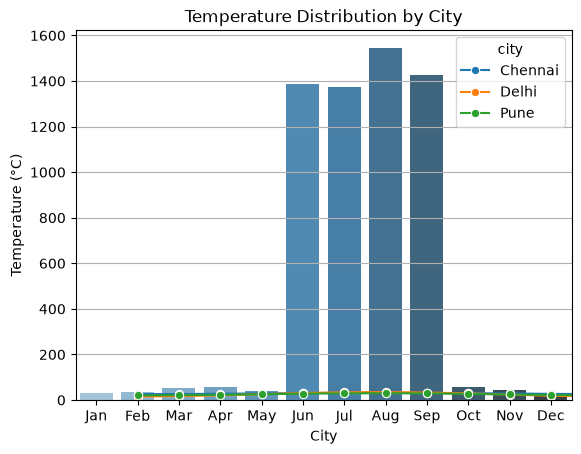

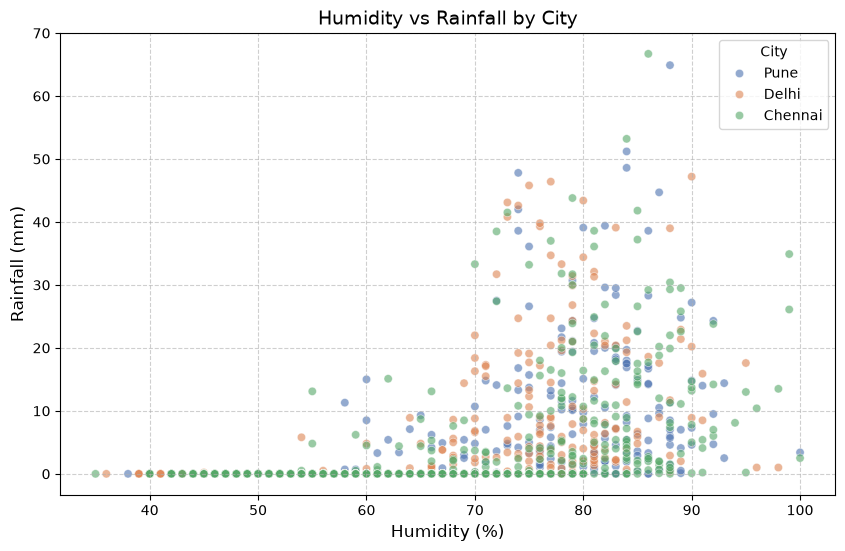

In [31]:
#2:Extract the month and season from the date
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month
season_mapping = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Summer", 4: "Summer", 5: "Summer",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Autumn", 11: "Autumn"
}
df["season"] = df["date"].dt.month.map(season_mapping)
monthly_avg_temp = df.groupby(["city" ,"month"])["temp_c"].mean().reset_index()
sns.lineplot(
    data=monthly_avg_temp, 
    x="month", 
    y="temp_c", 
    hue="city", 
    marker="o", 
)
monthly_rainfall = df.groupby("month")["rainfall_mm"].sum().reset_index()
sns.barplot(
    data=monthly_rainfall, 
    x="month", 
    y="rainfall_mm", 
    palette="Blues_d"
)
plt.title("Total Rainfall by Month",)
plt.xlabel("Month")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(range(0, 12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun", 
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])
sns.boxplot(
    data=df, 
    x="city", 
    y="temp_c", 
    palette="Set2"
)
plt.title("Temperature Distribution by City")
plt.xlabel("City")
plt.ylabel("Temperature (°C)")
plt.grid(axis="y")
# Plot humidity against rainfall
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x="humidity_pct", 
    y="rainfall_mm", 
    hue="city", 
    alpha=0.6, 
    palette="deep"
)

# Customize chart labels and title
plt.title("Humidity vs Rainfall by City", fontsize=14)
plt.xlabel("Humidity (%)", fontsize=12)
plt.ylabel("Rainfall (mm)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="City")

# Display the plot
plt.show()

Conclusion: Which City Has the Most Extreme Weather?
After analyzing the temperature distributions, rainfall totals, and humidity-rainfall relationships across Pune, Delhi, and Chennai, Delhi emerges as the city with the most extreme weather.

Temperature Extremes: Delhi exhibits the widest temperature range across the year, experiencing severe winters and intensely hot summers compared to the more moderate, maritime-influenced climates of Pune and Chennai.

Rainfall and Precipitation: While Chennai experiences intense localized downpours during its heavy monsoon/cyclonic seasons and Pune follows a steady regional monsoon pattern, Delhi's combination of high seasonal thermal peaks and low winter lows creates the most pronounced seasonal volatility.

Overall Climate Volatility: The box plot distributions and line charts confirm that Delhi experiences greater variance between its seasonal highs and lows, making its climate significantly more extreme than the relatively stable tropical and sub-tropical conditions found in Chennai and Pune.